<a href="https://colab.research.google.com/github/WellingtonRoque/MineracaoDados/blob/main/atividades/aula11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Aula 11 — Agrupamento (Clustering)

Descobrindo grupos e padrões sem utilizar rótulos

📐 4. Distância e similaridade
Para agrupar objetos, precisamos definir o que significa serem semelhantes.

Uma ideia simples é utilizar distância.

Considere dois pontos:

A = (2, 3)

B = (5, 7)

A distância euclidiana pode ser calculada por:

d = √((x₂-x₁)² + (y₂-y₁)²)

Quanto menor a distância, mais semelhantes os pontos podem ser considerados em relação às variáveis utilizadas.

O K-Means utiliza a ideia de distância para construir seus grupos.

💻 5. Preparando o ambiente

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

print("Ambiente preparado!")


Ambiente preparado!


🏭 6. Criando dados de motores

Vamos criar três perfis fictícios de motores:

Perfil A

Operação mais estável.

Perfil B

Temperatura e vibração maiores.

Perfil C

Corrente mais elevada.

O objetivo é verificar se o algoritmo consegue encontrar esses grupos sem receber os perfis como informação.

In [2]:
n = 300

grupo_a = pd.DataFrame({
    "temperatura": np.random.normal(60, 3, n//3),
    "vibracao": np.random.normal(1.5, 0.25, n//3),
    "corrente": np.random.normal(11, 0.8, n//3)
})

grupo_b = pd.DataFrame({
    "temperatura": np.random.normal(78, 3, n//3),
    "vibracao": np.random.normal(3.2, 0.35, n//3),
    "corrente": np.random.normal(13, 0.8, n//3)
})

grupo_c = pd.DataFrame({
    "temperatura": np.random.normal(68, 3, n//3),
    "vibracao": np.random.normal(1.9, 0.25, n//3),
    "corrente": np.random.normal(16, 0.8, n//3)
})

df = pd.concat([grupo_a, grupo_b, grupo_c], ignore_index=True)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.head()

,temperatura,vibracao,corrente
0,72.066914,1.547885,15.630180
1,67.235068,1.891253,16.228692
2,80.572979,2.854996,13.934226
3,61.627680,1.481389,14.082185
4,66.719357,1.474354,15.385762


In [3]:
df.describe()


,temperatura,vibracao,corrente
count,300.000000,300.000000,300.000000
mean,68.693754,2.194811,13.380864
std,8.150290,0.772985,2.265121
min,52.140765,1.020307,8.406986
25%,61.084728,1.574002,11.517619
50%,67.869428,1.946450,12.953473
75%,76.279173,2.876665,15.585976
max,84.569409,4.277608,18.021546


Vamos visualizar temperatura e vibração.

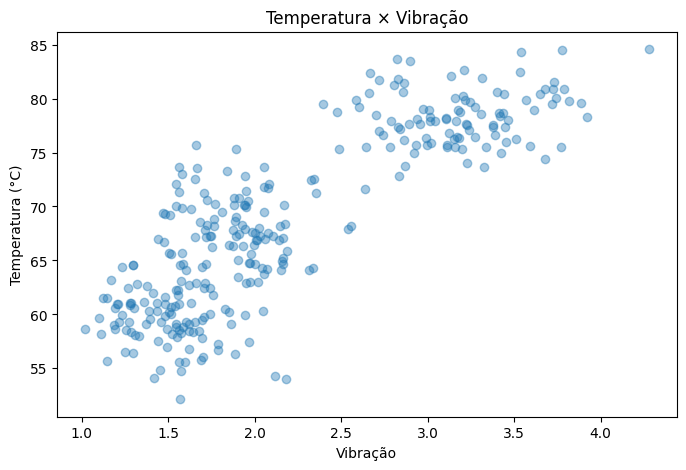

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df["vibracao"], df["temperatura"], alpha=0.4)
plt.title("Temperatura × Vibração")
plt.xlabel("Vibração")
plt.ylabel("Temperatura (°C)")
plt.show()

9. Por que normalizar?

Imagine duas variáveis:

Temperatura → aproximadamente 60 a 80

Corrente    → aproximadamente 10 a 18

Neste caso a diferença de escala não é tão grande.

Mas imagine:

Temperatura → 60

Pressão     → 100000

A variável pressão poderia dominar o cálculo de distância.

Por isso, geralmente normalizamos os dados antes do clustering.

In [7]:
X = df[["temperatura", "vibracao", "corrente"]]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[ 0.41456136, -0.83831903,  0.99468139],
       [-0.17927251, -0.39336591,  1.25935266],
       [ 1.45995694,  0.85549887,  0.2447049 ],
       [-0.86842063, -0.92448796,  0.31013484],
       [-0.24265347, -0.93360351,  0.88659614]])

10. Primeiro clustering

Vamos pedir ao K-Means para encontrar 3 grupos.

In [22]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["cluster"] = clusters

df.head()

,temperatura,vibracao,corrente,cluster
0,72.066914,1.547885,15.630180,1
1,67.235068,1.891253,16.228692,1
2,80.572979,2.854996,13.934226,2
3,61.627680,1.481389,14.082185,1
4,66.719357,1.474354,15.385762,1


11. Quantidade de registros por cluster

In [20]:
df["cluster"].value_counts().sort_index()


,count
cluster,
0,99
1,101
2,34
3,66


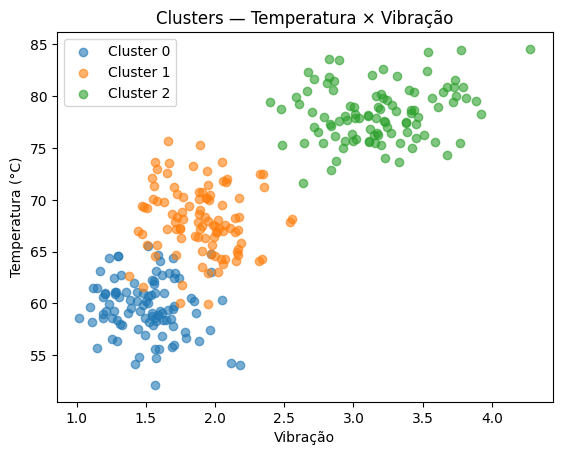

In [23]:
for cluster in sorted(df["cluster"].unique()):
    dados = df[df["cluster"] == cluster]
    plt.scatter(
        dados["vibracao"],
        dados["temperatura"],
        alpha=0.6,
        label=f"Cluster {cluster}"
    )

plt.title("Clusters — Temperatura × Vibração")
plt.xlabel("Vibração")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.show()

12. Analisando os centroides
O K-Means possui um centroide para cada grupo.

Vamos recuperar os centroides na escala original.

In [12]:
centroides = scaler.inverse_transform(kmeans.cluster_centers_)

centroides_df = pd.DataFrame(
    centroides,
    columns=["temperatura", "vibracao", "corrente"]
)

centroides_df

,temperatura,vibracao,corrente
0,59.668872,1.505820,11.021308
1,68.008474,1.894330,16.162120
2,78.320520,3.180398,12.907756


13. Perfil dos clusters

Outra forma de analisar é agrupar a própria base.

In [13]:

perfil_clusters = (
    df.groupby("cluster")[["temperatura", "vibracao", "corrente"]]
      .mean()
      .round(2)
)

perfil_clusters

,temperatura,vibracao,corrente
cluster,,,
0,59.67,1.51,11.02
1,68.01,1.89,16.16
2,78.32,3.18,12.91


📐 14. Método do cotovelo

Como saber quantos clusters devemos utilizar?

Uma técnica exploratória bastante conhecida é o método do cotovelo.

O K-Means possui uma medida chamada inertia_.

Ela representa, de forma simplificada, a soma das distâncias dos pontos até seus respectivos centroides.

Vamos testar vários valores de K.

In [14]:
inertias = []

for k in range(1, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    modelo.fit(X_scaled)
    inertias.append(modelo.inertia_)

inertias

[900.0,
 437.50665943349344,
 115.21967353298908,
 99.60596898913768,
 87.85674564828413,
 78.20641159945872,
 73.19957465758222,
 68.17838403606791,
 63.98848366603719,
 60.030079244656974]

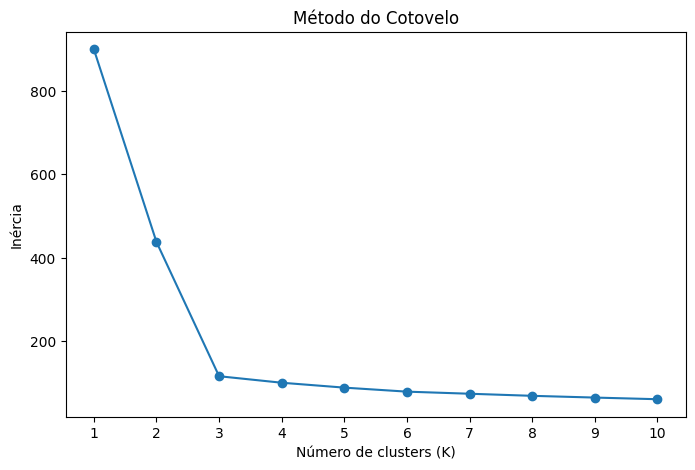

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertias, marker="o")
plt.title("Método do Cotovelo")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia")
plt.xticks(range(1, 11))
plt.show()

15. Testando diferentes valores de K

Vamos comparar alguns valores.

In [16]:
resultados_k = []

for k in [2, 3, 4, 5]:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = modelo.fit_predict(X_scaled)

    resultados_k.append({
        "k": k,
        "inertia": modelo.inertia_,
        "quantidade_grupos": len(np.unique(labels))
    })

pd.DataFrame(resultados_k)

,k,inertia,quantidade_grupos
0,2,437.506659,2
1,3,115.219674,3
2,4,99.605969,4
3,5,87.856746,5


16. Visualizando três variáveis

Temos três variáveis:

temperatura

vibracao

corrente

Um gráfico 2D consegue mostrar apenas duas dimensões ao mesmo tempo.

Podemos escolher duas variáveis e analisar a terceira por outro recurso, como tamanho dos pontos.

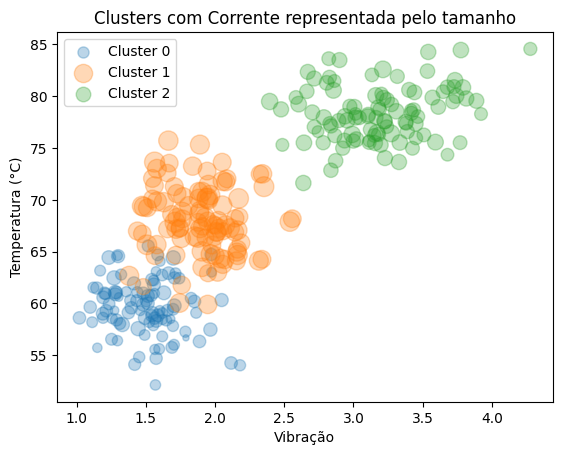

In [18]:
tamanho = (df["corrente"] - df["corrente"].min() + 1) * 20

for cluster in sorted(df["cluster"].unique()):
    dados = df[df["cluster"] == cluster]
    tamanhos = tamanho.loc[dados.index]

    plt.scatter(
        dados["vibracao"],
        dados["temperatura"],
        s=tamanhos,
        alpha=0.3,
        label=f"Cluster {cluster}"
    )

plt.title("Clusters com Corrente representada pelo tamanho")
plt.xlabel("Vibração")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.show()